# Mammalian cell cycle

This notebook reproduces the analysis of the cell cycle model of the [MaBoSS website](https://maboss.curie.fr).

The model is based on a published Boolean model of the mammalian cell cycle
([Fauré et al., 2006](https://doi.org/10.1093/bioinformatics/btl210)). It describes the signaling network
that controls the mammalian cell cycle. Mutants can be simulated with the parameters `$CycD_del`, `$Cdc20_del`
and `$Rb_del`: they are set to 0 for the wild type, and to 1 to simulate the corresponding deletion.

**Requirements:** [pyMaBoSS](https://pymaboss.readthedocs.io/), and the files `cellcycle.bnd`,
`cellcycle_runcfg.cfg` and `cellcycle_runcfg_randinit.cfg`, in the same folder as this notebook.

In [1]:
import math
import os
import maboss
import matplotlib.pyplot as plt
from matplotlib.offsetbox import HPacker

# The figures are saved in the "figures" folder
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"savefig.dpi": 150, "savefig.bbox": "tight", "figure.constrained_layout.use": True})

def legend_below():
    """Move the legend of the current figure below the plot, in centered rows of similar widths."""
    figure, legend = plt.gcf(), plt.gca().get_legend()
    handles, labels = legend.legend_handles, [text.get_text() for text in legend.get_texts()]
    legend.remove()
    legend = figure.legend(handles, labels, loc="outside lower center", ncols=1)
    # Matplotlib fills the rows from the left: we rearrange the entries of the legend in centered rows,
    # as few as possible within the width of the plot, and of similar widths
    column = legend._legend_handle_box.get_children()[0]
    entries, column.align = column.get_children(), "center"
    sep = legend.columnspacing * legend.prop.get_size_in_points() * figure.dpi / 72
    widths = [entry.get_bbox(figure.canvas.get_renderer()).width + sep for entry in entries]
    max_width = 0.8 * figure.get_figwidth() * figure.dpi
    for n_rows in range(math.ceil(sum(widths) / max_width), len(entries) + 1):
        rows, row_widths = [[]], [0]
        for entry, width in zip(entries, widths):
            if rows[-1] and row_widths[-1] + width / 2 > sum(widths) / n_rows:
                rows.append([])
                row_widths.append(0)
            rows[-1].append(entry)
            row_widths[-1] += width
        if max(row_widths) <= max_width:
            break
    column._children = [HPacker(sep=sep, align="baseline", children=row) for row in rows]

## The model

The output nodes are the four cyclins: CycD, CycE, CycA and CycB.

In [2]:
sim = maboss.load("cellcycle.bnd", "cellcycle_runcfg.cfg")
sim.print_bnd()

Node CycD {

	logic = CycD;
	rate_up = (NOT $CycD_del) ? 0.0 : 0.0;
	rate_down = $CycD_del ? $fast : 0.0;
}
Node CycE {

	logic = !Rb & E2F;
	rate_up = @logic ? $slow : 0.0;
	rate_down = @logic ? 0.0 : $fast;
}

Node CycA {

	logic = !Rb & !Cdc20 & !(UbcH10 & cdh1) & (CycA | E2F);
	rate_up = @logic ? $slow : 0.0;
	rate_down = @logic ? 0.0 : $fast;
}

Node CycB {

	logic = !Cdc20 & !cdh1;
	rate_up = @logic ? $slow : 0.0;
	rate_down = @logic ? 0.0 : $fast;
}

Node Rb {

	logic = !CycD & !CycB & (p27 | !(CycA | CycE));
	rate_up = (@logic AND (NOT $Rb_del)) ? $fast : 0.0;
	rate_down = (@logic AND (NOT $Rb_del)) ? 0.0 : $fast;
}

Node E2F {

	logic = !Rb & !CycB & (!CycA | p27);
	rate_up = @logic ? $slow : 0.0;
	rate_down = @logic ? 0.0 : $fast;
}

Node p27 {

	logic = !CycD & !CycB & (!(CycA | CycE) | (p27 & !(CycE & CycA)));
	rate_up = @logic ? $fast : 0.0;
	rate_down = @logic ? 0.0 : $fast;
}

Node Cdc20 {

	logic = CycB;
	rate_up = (@logic AND (NOT $Cdc20_del)) ? $slow : 0.0;
	rate_down

## Dynamics from the start of the cell cycle

The first configuration file sets the initial condition corresponding to the start of the cell cycle
(CycD, Rb, p27 and cdh1 active). The configuration files use the physical random generator: we use instead
the pseudo-random generator, with a fixed seed, to make the results reproducible, and 4 threads.

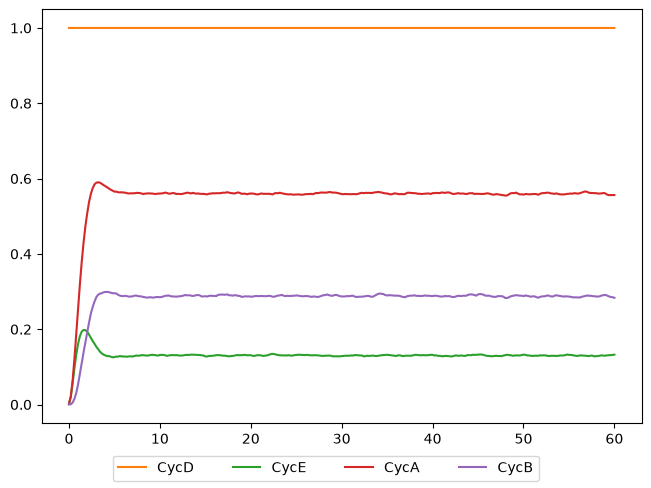

In [3]:
sim.update_parameters(use_physrandgen=0, thread_count=4)
result = sim.run()
result.plot_node_trajectory(until=60)
legend_below()
plt.savefig("figures/cellcycle_cyclins.png")

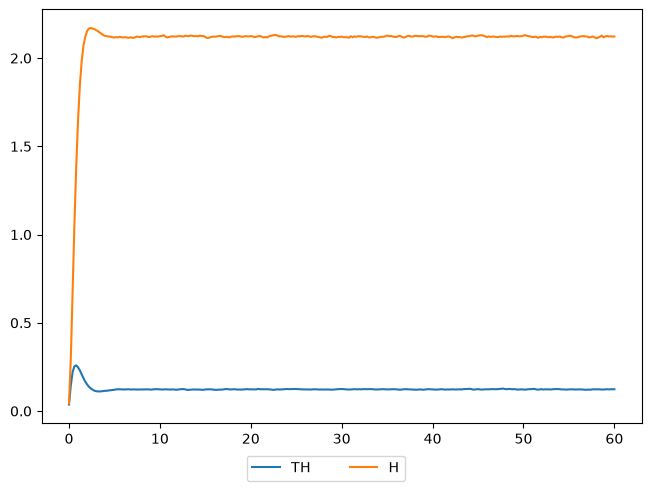

In [4]:
result.plot_entropy_trajectory(until=60)
legend_below()
plt.savefig("figures/cellcycle_entropies.png")

## Asymptotic behaviour, from a random initial condition

The second configuration file uses a random initial condition. At the end of the simulation, about half of the
cells are in the state where no cyclin is active (`<nil>`): this is a fixed point, which represents the G1 phase.
In the other half, CycD is active and the other cyclins keep cycling: this represents a desynchronized
proliferating cell population.

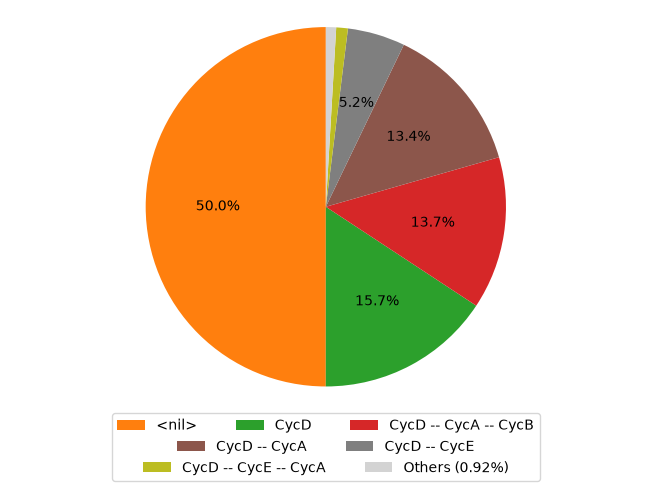

In [5]:
sim_random = maboss.load("cellcycle.bnd", "cellcycle_runcfg_randinit.cfg")
sim_random.update_parameters(use_physrandgen=0, thread_count=4)
result_random = sim_random.run()
result_random.plot_piechart()
legend_below()
plt.savefig("figures/cellcycle_final_states.png")